# C2 · Train and explain a first model
## Will a driver score points? A pre-race classifier for Formula 1 (2014–2024)
**Business Intelligence · IIB423T-1 · Universidad del Desarrollo** — **Group 06**: Maximiliano Sandoval Mosser and Benjamín Toloza Cossio ·
Instructor: Tomás Fontecilla · C2 · November 2026

**Data source.** *Formula 1 World Championship (1950–2024)*, Kaggle (user rohanrao), data from the Ergast API, downloaded on
10 September 2026. Public data. This notebook reuses the analytic table and the train/test split built in W2
(`data/processed/analytic_driver_race_2014_2024_w2.csv` and `data/processed/w2_split_assignment.csv`).

**Reading order.** `1_W2_preparation_and_split.ipynb` (W2: data preparation, validation, leakage audit and split design) →
**`2_C2_model.ipynb` (this notebook)**. Repository: https://github.com/BeTRoCo/GROUP_06_C1

**Route: classification.** Text blocks are labelled **Observation**, **Assumption** and **Managerial recommendation**.

## 1. Task
| Element | Definition |
|---|---|
| **Question** | Before the start of a Grand Prix, how well can we anticipate which drivers will finish in the points (top 10)? |
| **One row** | One driver in one race (`raceId` + `driverId`), seasons 2014–2024: 4,606 rows, 227 races. |
| **Target (positive class)** | `top10 = 1`: the driver finishes 1st–10th and scores points. Exactly 10 drivers per race are positive (about 49 % of rows). |
| **When the prediction is made** | **T1**: after qualifying and penalties, when the starting grid is published, and before the start. |
| **Inputs available at T1** | grid slot (or pit-lane start), team's championship rank after the previous round, qualifying gap to the fastest qualifier. |
| **User** | A team strategist (our proposal since W1), who uses the prediction as a planning input for the race. |

### How we used the W2 feedback
| W2 feedback | What we did in C2 | Where |
|---|---|---|
| "If you model results, keep whole races in each partition." | The split is by **season** (development 2014–2022, test 2023–2024), so every race lies entirely in one subset. Validation folds are also whole seasons. Checked by assertions. | Parts 2, 4 |
| "Use only information available before the start." | Only the three T1 inputs above. Everything observed during or after the race (lap-1 position, race pace, status, points) is excluded by an assertion. Imputation and scaling are fitted on training data only. | Parts 3, 4 |
| "Evaluate results by regulation period." | Validation results are reported separately for the 2014–2021 rules (folds 2018–2021) and the 2022 rules (fold 2022). The test seasons are all under the 2022 rules. | Parts 4, 5 |
| "Avoid causal attributions to rank relationships." | Coefficients and comparisons are described as associations used for prediction, never as the effect of moving up the grid. | Part 6 |

Retained from W2 without change: the analytic table, the definition of the target, and the decision not to use the test seasons
for any choice.

## 2. Data and the W2 split

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def find_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "raw" / "races.csv").exists():
            return base
    raise FileNotFoundError("data/raw/races.csv not found: open the whole GROUP_06_C1 folder.")

ROOT = find_root()
PROC, FIG = ROOT / "data" / "processed", ROOT / "analysis" / "figures"
SEED = 2026
BLUE, ORANGE, AQUA, GREY, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e", "#e6e6e3"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#bdbcb7", "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "font.size": 9.5, "legend.frameon": False})
def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

at = pd.read_csv(PROC / "analytic_driver_race_2014_2024_w2.csv", parse_dates=["date"])
split = pd.read_csv(PROC / "w2_split_assignment.csv")
df = at.merge(split[["raceId", "driverId", "split"]], on=["raceId", "driverId"], how="left", validate="one_to_one")
assert df["split"].notna().all() and len(df) == 4606
df["period"] = np.where(df["year"] >= 2022, "2022 rules (2022–2024)", "2014–2021 rules")

dev, test = df[df["split"] == "development"].copy(), df[df["split"] == "test"].copy()
assert set(dev["raceId"]).isdisjoint(test["raceId"])                  # no race shared between subsets
assert dev["date"].max() < test["date"].min()                          # development strictly before test
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
pd.DataFrame({
    "seasons": [f"{d['year'].min()}–{d['year'].max()}" for d in (dev, test)],
    "races": [d["raceId"].nunique() for d in (dev, test)], "rows": [len(d) for d in (dev, test)],
    "share of rows": [f"{len(d) / len(df):.1%}" for d in (dev, test)],
    "positives (top 10)": [int(d["top10"].sum()) for d in (dev, test)],
    "prevalence": [f"{d['top10'].mean():.1%}" for d in (dev, test)],
    "use": ["training + validation (season folds)", "final evaluation only, once (part 5)"]},
    index=["development", "test"])

pandas 3.0.2 | scikit-learn 1.9.1


,seasons,races,rows,share of rows,positives (top 10),prevalence,use
development,2014–2022,181,3687,80.0%,1810,49.1%,training + validation (season folds)
test,2023–2024,46,919,20.0%,460,50.1%,"final evaluation only, once (part 5)"


**Observation.** Development has 181 races and test 46 races, with no race in both. The prevalence of the positive class
is close to 50 % in both subsets because exactly 10 drivers per race score points.

## 3. Inputs and preparation (pre-start information only)
| Input | Meaning | Available at T1? | Preparation |
|---|---|---|---|
| `grid_filled` | grid slot; a pit-lane start is placed **behind the last slot** (slot = number of starters) | yes, published grid | fixed rule, no learning |
| `pitlane` | 1 if the driver starts from the pit lane | yes | none |
| `constructor_rank_prev` | team's championship rank after the **previous** round (round 1: previous season) | yes (W2 check C14) | median imputation (4 rows missing) |
| `quali_gap_pct` | best qualifying time, % slower than the fastest qualifier of that race | yes, after qualifying | median imputation (67 missing) |

All four inputs are standardised (mean 0, standard deviation 1) so the coefficients are comparable. **The imputer and the scaler
are fitted inside a pipeline on training data only** and re-fitted in every validation fold.

In [2]:
df["grid_filled"] = df["grid"].fillna(df["starters_in_race"])      # rule: pit lane = behind the last grid slot
df["pitlane"] = df["pitlane_start"].astype(int)
dev, test = df[df["split"] == "development"].copy(), df[df["split"] == "test"].copy()

FEATURES = ["grid_filled", "pitlane", "constructor_rank_prev", "quali_gap_pct"]
TARGET = "top10"
AFTER_START = ["pos_lap1", "gained_lap1", "race_pace_gap_pct", "fastest_lap_rank", "final_pos", "position",
               "positions_gained", "finished", "classified", "status", "points", "laps", "circuit_races"]
assert not set(FEATURES) & set(AFTER_START + [TARGET])                 # leakage guard (W2 part 5)

def make_model():
    prep = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                                                ("scale", StandardScaler())]), FEATURES)])
    return Pipeline([("prep", prep), ("logit", LogisticRegression(C=1.0, max_iter=1000))])

def baseline(d):
    """Reference rule 'you finish where you start': points predicted for grid slots 1–10 (pit lane = no)."""
    return (d["grid"] <= 10).astype(int).to_numpy()

THRESHOLD = 0.5
print("Missing values in development:", dev[FEATURES].isna().sum().to_dict())

Missing values in development: {'grid_filled': 0, 'pitlane': 0, 'constructor_rank_prev': 4, 'quali_gap_pct': 58}


## 4. Model, reference and validation (development seasons only)
**Model: logistic regression** (class 8). The target is binary, the model gives a probability that can be explained, and four
inputs are enough for a first model. Settings: L2 regularisation with `C = 1.0` (scikit-learn default), standardised inputs,
`max_iter = 1000`. **Decision threshold 0.5**: classes are balanced (about 49 % positives), and for a planning input we treat
a false alarm and a missed scorer as similarly costly (part 5.3). This choice is checked on validation below, not on test.

**Reference (baseline): "you finish where you start."** Predict points for every driver who starts 1st–10th. It needs no
training and is the rule a strategist would use without a model.

**Validation: expanding window by season** (designed in W2). For each season *v* from 2018 to 2022, the model is trained on all
earlier development seasons and evaluated on *v*. Both the model and the reference are scored on the **same records**.

In [3]:
def scores(y, yhat):
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat),
            "recall": recall_score(y, yhat), "F1": f1_score(y, yhat)}

rows, val_probs = [], []
for v in range(2018, 2023):
    tr, va = dev[dev["year"] < v], dev[dev["year"] == v]
    assert set(tr["raceId"]).isdisjoint(va["raceId"]) and tr["date"].max() < va["date"].min()
    m = make_model().fit(tr[FEATURES], tr[TARGET])
    p = m.predict_proba(va[FEATURES])[:, 1]
    val_probs.append(pd.DataFrame({"year": v, "y": va[TARGET].to_numpy(), "p": p, "base": baseline(va)}))
    for name, yhat in [("model", (p >= THRESHOLD).astype(int)), ("reference", baseline(va))]:
        rows.append({"validation season": v, "period": "2022 rules" if v >= 2022 else "2014–2021 rules",
                     "train seasons": f"2014–{v - 1}", "races": va["raceId"].nunique(), "who": name,
                     **scores(va[TARGET], yhat), "predicted positive rate": yhat.mean()})
val = pd.DataFrame(rows)
display(val.pivot_table(index=["validation season", "period", "races"], columns="who", values=["F1", "accuracy"]).round(3))

vp = pd.concat(val_probs)
vp["period"] = np.where(vp["year"] >= 2022, "2022 rules (fold 2022)", "2014–2021 rules (folds 2018–2021)")
by_period = pd.DataFrame({
    (per, who): scores(g["y"], (g["p"] >= THRESHOLD).astype(int) if who == "model" else g["base"])
    for per, g in vp.groupby("period") for who in ("model", "reference")}).T
by_period.index.names = ["regulation period", "who"]
display(by_period.round(3))

F1           accuracy          
who                                      model reference    model reference
validation season period          races                                    
2018              2014–2021 rules 21     0.738     0.743    0.750     0.743
2019              2014–2021 rules 21     0.723     0.743    0.733     0.743
2020              2014–2021 rules 17     0.761     0.747    0.756     0.747
2021              2014–2021 rules 21     0.794     0.771    0.790     0.771
2022              2022 rules      22     0.746     0.731    0.755     0.732

accuracy  precision  recall  \
regulation period                 who                                      
2014–2021 rules (folds 2018–2021) model         0.758      0.764   0.745   
                                  reference     0.751      0.751   0.751   
2022 rules (fold 2022)            model         0.755      0.772   0.723   
                                  reference     0.732      0.734   0.727   

                                                F1  
regulation period                 who               
2014–2021 rules (folds 2018–2021) model      0.754  
                                  reference  0.751  
2022 rules (fold 2022)            model      0.746  
                                  reference  0.731

Validation prevalence: 0.500 | predicted positive rate at 0.5: 0.483


,0,1,2,3,4,5,6,7,8
threshold,0.300,0.350,0.400,0.450,0.500,0.550,0.600,0.650,0.700
"F1 (validation, pooled)",0.769,0.777,0.776,0.767,0.753,0.735,0.716,0.696,0.671
predicted positive rate,0.670,0.613,0.571,0.525,0.483,0.446,0.408,0.370,0.339


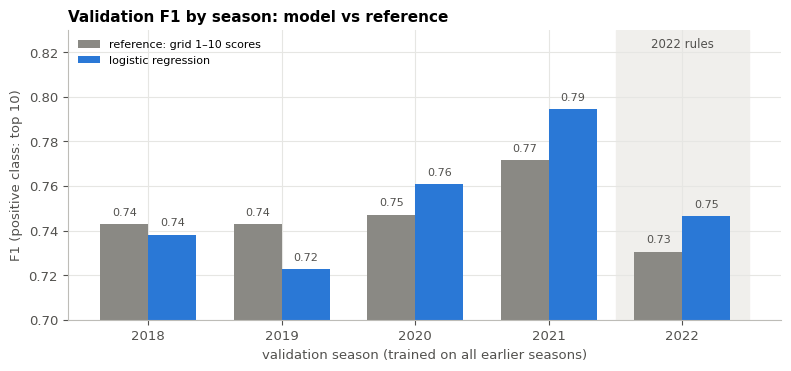

In [4]:
# Check of the threshold choice on VALIDATION records only (test is not used)
grid_t = np.round(np.arange(0.30, 0.71, 0.05), 2)
thr = pd.DataFrame({"threshold": grid_t,
                    "F1 (validation, pooled)": [f1_score(vp["y"], (vp["p"] >= t).astype(int)) for t in grid_t],
                    "predicted positive rate": [(vp["p"] >= t).mean() for t in grid_t]})
print(f"Validation prevalence: {vp['y'].mean():.3f} | predicted positive rate at 0.5: {(vp['p'] >= .5).mean():.3f}")
display(thr.round(3).T)

fig, ax = plt.subplots(figsize=(8, 3.8))
piv = val.pivot(index="validation season", columns="who", values="F1")
x = np.arange(len(piv))
ax.axvspan(3.5, 4.5, color="#f0efec", zorder=0)
ax.text(4, 0.822, "2022 rules", ha="center", fontsize=8.5, color=INK2)
ax.bar(x - 0.18, piv["reference"], 0.36, color=GREY, label="reference: grid 1–10 scores")
ax.bar(x + 0.18, piv["model"], 0.36, color=BLUE, label="logistic regression")
for i, (r, mo) in enumerate(zip(piv["reference"], piv["model"])):
    ax.text(i - 0.18, r + 0.004, f"{r:.2f}", ha="center", fontsize=8, color=INK2)
    ax.text(i + 0.18, mo + 0.004, f"{mo:.2f}", ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, [str(s) for s in piv.index])
ax.set(ylim=(0.70, 0.83), xlabel="validation season (trained on all earlier seasons)", ylabel="F1 (positive class: top 10)",
       title="Validation F1 by season: model vs reference")
ax.legend(loc="upper left", fontsize=8)
save_fig(fig, "C2_01_validation_f1_by_season")

**Observation.**
- **By season.** The model is slightly below the reference in 2018 and 2019 (F1 0.738 vs 0.743 and 0.723 vs 0.743) and above it
  from 2020 to 2022 (up to 0.794 vs 0.771 in 2021). With fewer training seasons the model gains little over the grid alone.
- **By regulation period.** Under the 2014–2021 rules (folds 2018–2021) model and reference are practically tied (F1 0.754 vs
  0.751). Under the 2022 rules (fold 2022, trained only on older seasons) the model is ahead (0.746 vs 0.731). One season is a
  small sample, so this is a signal, not a proof.
- **Threshold check (validation only).** At 0.5 the model predicts points for 48.3 % of drivers, close to the real 50.0 %, so it
  predicts about 10 scorers per race, like reality. A lower threshold (0.35–0.40) gives a slightly higher F1 (0.78) but predicts
  points for 57–61 % of drivers, i.e. 11–12 "scorers" per race, which over-promises points. We keep 0.5 because it matches the
  real number of points places and treats both errors alike (part 5.3). The test seasons were not used for this check.

## 5. Final evaluation on the test seasons (2023–2024)
The specification is now frozen: four inputs, logistic regression with `C = 1.0`, threshold 0.5. The model is re-trained on all
development seasons (2014–2022) and evaluated **once** on the test seasons. The reference is scored on the same 919 test rows.

,accuracy,precision,recall,F1,correct predictions
logistic regression,0.814,0.820,0.804,0.812,748
reference (grid 1–10),0.790,0.791,0.789,0.790,726


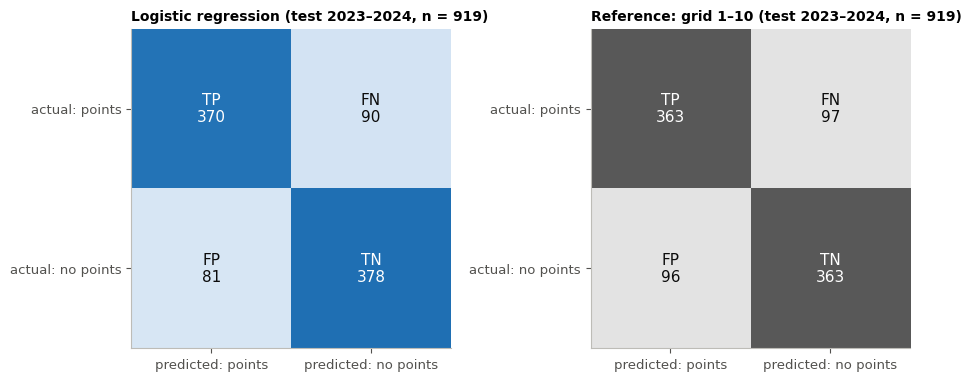

In [5]:
final = make_model().fit(dev[FEATURES], dev[TARGET])                 # preparation + model fitted on development only
p_test = final.predict_proba(test[FEATURES])[:, 1]
yhat_model = (p_test >= THRESHOLD).astype(int)
yhat_ref = baseline(test)
y_test = test[TARGET].to_numpy()

res = pd.DataFrame({"logistic regression": scores(y_test, yhat_model), "reference (grid 1–10)": scores(y_test, yhat_ref)}).T
res["correct predictions"] = [int((yhat_model == y_test).sum()), int((yhat_ref == y_test).sum())]
display(res.round(3))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.9))
for ax, (name, yhat), cmap in zip(axes, [("Logistic regression", yhat_model), ("Reference: grid 1–10", yhat_ref)], ["Blues", "Greys"]):
    cm = confusion_matrix(y_test, yhat, labels=[1, 0])
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=500)
    labels = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=11,
                    color="white" if cm[i, j] > 250 else "#0b0b0b")
    ax.set_xticks([0, 1], ["predicted: points", "predicted: no points"]); ax.set_yticks([0, 1], ["actual: points", "actual: no points"])
    ax.grid(False); ax.set_title(f"{name} (test 2023–2024, n = {len(y_test)})", fontsize=10)
save_fig(fig, "C2_02_test_confusion_matrices")

In [6]:
# Uncertainty of the difference: bootstrap of WHOLE test races (rows of one race are resampled together)
rng = np.random.default_rng(SEED)
t = test.assign(m=yhat_model, r=yhat_ref)
by_race = {rid: g for rid, g in t.groupby("raceId")}
ids = np.array(list(by_race))
diff = []
for _ in range(2000):
    s = pd.concat([by_race[r] for r in rng.choice(ids, len(ids))])
    diff.append(f1_score(s[TARGET], s["m"]) - f1_score(s[TARGET], s["r"]))
lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"F1 model − reference on test: {res.loc['logistic regression', 'F1'] - res.loc['reference (grid 1–10)', 'F1']:+.3f} "
      f"(95 % race-bootstrap interval {lo:+.3f} to {hi:+.3f})")
for season, g in t.groupby("year"):
    print(f"Season {season} ({g['raceId'].nunique()} races, 2022 rules): F1 model {f1_score(g[TARGET], g['m']):.3f} | "
          f"reference {f1_score(g[TARGET], g['r']):.3f}")

F1 model − reference on test: +0.022 (95 % race-bootstrap interval -0.001 to +0.047)
Season 2023 (22 races, 2022 rules): F1 model 0.798 | reference 0.738
Season 2024 (24 races, 2022 rules): F1 model 0.826 | reference 0.838


**Observation.**
- **Test confusion matrix (positive = points).** The model gets 748 of 919 rows right (accuracy 0.814) against 726 for the
  reference (0.790). It has fewer false negatives (90 vs 97) **and** fewer false positives (81 vs 96), so precision (0.820 vs 0.791)
  and recall (0.804 vs 0.789) both improve; F1 0.812 vs 0.790.
- **The gain is small and uncertain.** Resampling whole test races, the F1 difference is +0.022 with a 95 % interval from −0.001
  to +0.047: compatible with a small improvement, but not with a large one, and it almost includes zero.
- **By season (both under the 2022 rules).** The model is clearly better in 2023 (0.798 vs 0.738) and slightly worse in 2024
  (0.826 vs 0.838). The advantage is not stable from one season to the next.

### 5.3 Why accuracy alone is not enough, and what each error costs
- **Accuracy hides the type of error.** About half of the drivers score points, so even a rule that ignores the data entirely is
  right about half the time, and two rules with the same accuracy can make very different mistakes. Precision and recall show
  whether a rule tends to over-promise points or to miss scorers.
- **Positive class: "finishes in the points".**
- **False positive** (predicted points, no points): the strategist expects points that do not come, for example by planning a
  conservative race to protect a position that is lost anyway. Many of these are retirements (part 6).
- **False negative** (predicted no points, scored): the team undervalues a car that can score and may not prepare an attacking
  strategy (tyres, undercut) to fight for the last points places.
- **Threshold.** We kept 0.5 because both errors lead to a poorly prepared race of similar cost for a planning input, the classes
  are balanced, and validation showed the predicted positive rate at 0.5 close to the real prevalence (part 4).

## 6. What the model adds, one limit and one improvement

In [7]:
coef = pd.Series(final.named_steps["logit"].coef_[0], index=FEATURES)
disagree = t[t["m"] != t["r"]]
fp = t[(t["m"] == 1) & (t[TARGET] == 0)]
print("Standardised coefficients (change in log-odds per 1 SD, other inputs fixed):", coef.round(2).to_dict())
print(f"Test rows where model and reference disagree: {len(disagree)} | model right in {int((disagree['m'] == disagree[TARGET]).sum())}")
print(f"  model says points but grid > 10 (reference says no): {int(((disagree['m'] == 1)).sum())}, "
      f"of which scored: {int(((disagree['m'] == 1) & (disagree[TARGET] == 1)).sum())}")
print(f"  model says no points but grid 1–10 (reference says yes): {int(((disagree['m'] == 0)).sum())}, "
      f"of which did not score: {int(((disagree['m'] == 0) & (disagree[TARGET] == 0)).sum())}")
print(f"Model false positives: {len(fp)} | of which the car did not finish the race: {int((~fp['finished']).sum())} "
      f"({(~fp['finished']).mean():.0%})")
disagree.groupby("m")["team_tier"].value_counts().unstack(fill_value=0).rename(index={0: "model: no points (grid 1–10)", 1: "model: points (grid > 10)"})

Standardised coefficients (change in log-odds per 1 SD, other inputs fixed): {'grid_filled': -0.86, 'pitlane': 0.02, 'constructor_rank_prev': -0.8, 'quali_gap_pct': -0.22}
Test rows where model and reference disagree: 102 | model right in 62
  model says points but grid > 10 (reference says no): 47, of which scored: 31
  model says no points but grid 1–10 (reference says yes): 55, of which did not score: 31
Model false positives: 81 | of which the car did not finish the race: 40 (49%)


team_tier,4th–6th,7th+,top 3
m,,,
model: no points (grid 1–10),0,55,0
model: points (grid > 10),12,0,35


**What the model adds.** The reference uses only the grid. The model adds the team's strength before the race and the
qualifying gap, and this changes the prediction in 102 of 919 test rows. In those disagreements the model is right 62 times (61 %):
it predicts points for 47 drivers starting outside the top 10 (all from teams ranked 1st–6th; 31 of them scored), and no points
for 55 drivers starting in the top 10 (all from teams ranked 7th or lower; 31 of them did not score). In short, it corrects the
grid for strong cars starting further back and weak cars starting near the front.

**How to read the coefficients (no causal claim).** The coefficients are **associations** used for prediction: among drivers
with the same team rank and qualifying gap, a worse grid slot goes with lower odds of scoring. They do not say that moving a car up
the grid *would* raise its chance of scoring: grid, qualifying gap and team rank move together (W2: Spearman 0.71–0.96), drivers
in different slots differ in car, driver and reliability, and nothing here was assigned at random. A useful prediction does not
prove that acting on it improves the result.

**Important limit.** Retirements cannot be known before the start. Of the model's 81 false positives, 40 (49 %) are
cars that did not finish the race (crashes or failures). No pre-start input in our data can anticipate them, so part of the error
is not reducible with these inputs. A second limit is the evidence base: the test covers only two seasons of one regulation period,
and the gain over the reference is small and uncertain (part 5).

**Possible improvement.** Add pre-start information on **reliability and recent form**, computed only from earlier races (for
example the team's retirement rate and average finishing position over its previous races, with a `shift` so the current race is
never included), and test whether training separately by regulation period helps for the 2022 rules. Both would be checked on the
same season folds before touching the test seasons again.

## 7. Contributions and AI use
**Contributions.** Benjamín Toloza prepared this notebook (data reuse from W2, model, reference, validation and test evaluation)
with AI assistance. Maximiliano Sandoval and Benjamín Toloza reviewed the results together, prepared the brief and the
presentation, and both present and answer questions.

**AI use.** Claude (Anthropic, Cowork mode) was used to plan the notebook against the C2 brief and the W2 feedback, to draft code
and text, and to propose the error analysis. We checked its suggestions by running the notebook from top to bottom, comparing
every number in the text, brief and slides with the printed outputs, and confirming that the test seasons were used only once,
after the specification was fixed on the validation folds.